In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
import matplotlib.pyplot as plt
import os

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Используем устройство: {device}")

DATA_DIR = "../data/raw/NEU-DET-organized"
train_dir = os.path.join(DATA_DIR, 'train')

train_transforms = transforms.Compose([
    transforms.Resize((224, 224)), # ResNet ожидает 224x224
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

full_dataset = datasets.ImageFolder(root=DATA_DIR, transform=train_transforms)

train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size

train_dataset, val_dataset = torch.utils.data.random_split(full_dataset, [train_size, val_size])

val_dataset.dataset.transform = val_transforms

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=0)

print(f"Размер train набора: {len(train_dataset)} изображений")
print(f"Размер val набора: {len(val_dataset)} изображений")
print(f"Классы: {full_dataset.classes}")

Используем устройство: cpu
Размер train набора: 1440 изображений
Размер val набора: 360 изображений
Классы: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']


In [2]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

for param in model.parameters():
    param.requires_grad = False

num_ftrs = model.fc.in_features
model.fc = nn.Linear(in_features=num_ftrs, out_features=6)

for param in model.fc.parameters():
    param.requires_grad = True

model = model.to(device)

print("Модель готова!")
print(f"Последний слой: {model.fc}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\User/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


Модель готова!
Последний слой: Linear(in_features=512, out_features=6, bias=True)


In [3]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)
num_epochs = 10

best_val_acc = 0.0
best_model_wts = None

train_losses, val_losses = [], []
train_accs, val_accs = [], []

print("Начинаем обучение...")

for epoch in range(num_epochs):
    print(f"\nEpoch {epoch+1}/{num_epochs}")
    print("-" * 10)

    model.train()
    running_loss = 0.0
    correct_preds = 0
    total_samples = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        correct_preds += torch.sum(preds == labels.data)
        total_samples += inputs.size(0)

    epoch_train_loss = running_loss / total_samples
    epoch_train_acc = correct_preds.double() / total_samples

    model.eval()
    val_running_loss = 0.0
    val_correct_preds = 0
    val_total_samples = 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct_preds += torch.sum(preds == labels.data)
            val_total_samples += inputs.size(0)

    epoch_val_loss = val_running_loss / val_total_samples
    epoch_val_acc = val_correct_preds.double() / val_total_samples

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)
    train_accs.append(epoch_train_acc.item())
    val_accs.append(epoch_val_acc.item())

    print(f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.4f}")
    print(f"Val Loss:   {epoch_val_loss:.4f} | Val Acc:   {epoch_val_acc:.4f}")

    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc
        best_model_wts = model.state_dict().copy()
        print(f"✨ Новая лучшая модель сохранена! Val Acc: {best_val_acc:.4f}")

model.load_state_dict(best_model_wts)

MODEL_SAVE_PATH = "../data/models/best_resnet18_defect.pth"
os.makedirs(os.path.dirname(MODEL_SAVE_PATH), exist_ok=True)
torch.save(model.state_dict(), MODEL_SAVE_PATH)
print(f"\n🏆 Обучение завершено! Лучшая модель сохранена в {MODEL_SAVE_PATH}")

Начинаем обучение...

Epoch 1/10
----------
Train Loss: 0.9868 | Train Acc: 0.7090
Val Loss:   0.6723 | Val Acc:   0.8361
✨ Новая лучшая модель сохранена! Val Acc: 0.8361

Epoch 2/10
----------
Train Loss: 0.3057 | Train Acc: 0.9556
Val Loss:   0.1799 | Val Acc:   0.9750
✨ Новая лучшая модель сохранена! Val Acc: 0.9750

Epoch 3/10
----------
Train Loss: 0.1954 | Train Acc: 0.9674
Val Loss:   0.1211 | Val Acc:   0.9833
✨ Новая лучшая модель сохранена! Val Acc: 0.9833

Epoch 4/10
----------
Train Loss: 0.1378 | Train Acc: 0.9792
Val Loss:   0.0948 | Val Acc:   0.9861
✨ Новая лучшая модель сохранена! Val Acc: 0.9861

Epoch 5/10
----------
Train Loss: 0.1145 | Train Acc: 0.9819
Val Loss:   0.0792 | Val Acc:   0.9861

Epoch 6/10
----------
Train Loss: 0.1032 | Train Acc: 0.9847
Val Loss:   0.0697 | Val Acc:   0.9889
✨ Новая лучшая модель сохранена! Val Acc: 0.9889

Epoch 7/10
----------
Train Loss: 0.0825 | Train Acc: 0.9868
Val Loss:   0.0605 | Val Acc:   0.9889

Epoch 8/10
----------
Trai

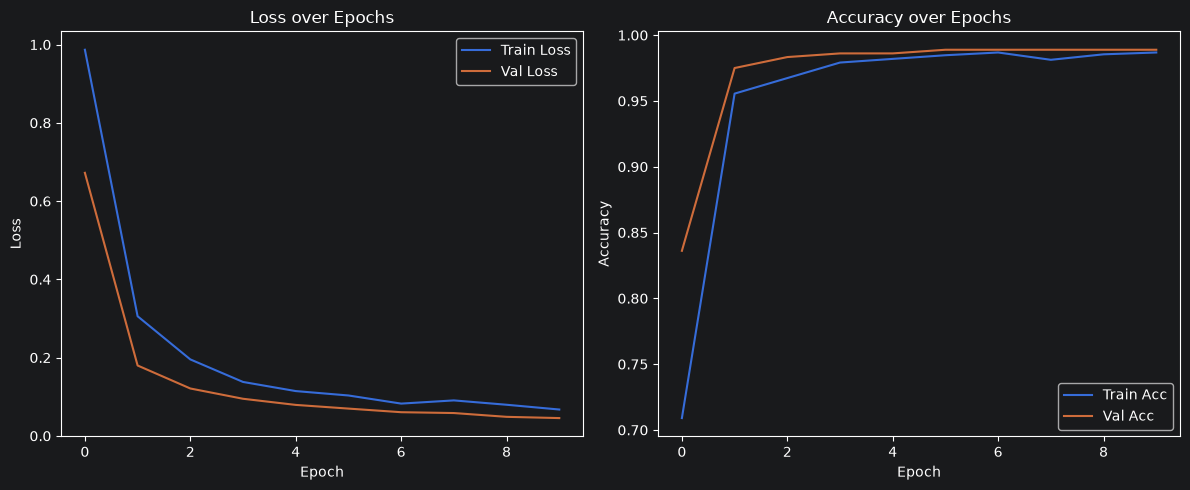

In [4]:
# График Loss
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# График Accuracy
plt.subplot(1, 2, 2)
plt.plot(train_accs, label='Train Acc')
plt.plot(val_accs, label='Val Acc')
plt.title('Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()